# CIFAR-100 subset CNN Comparison


## 1. Data loading and class-balanced split
Expected sizes: 32,000 training, 8,000 validation, and 8,000 test images.

Classes: 80
Training images: 32000
Validation images: 8000
Test images: 8000


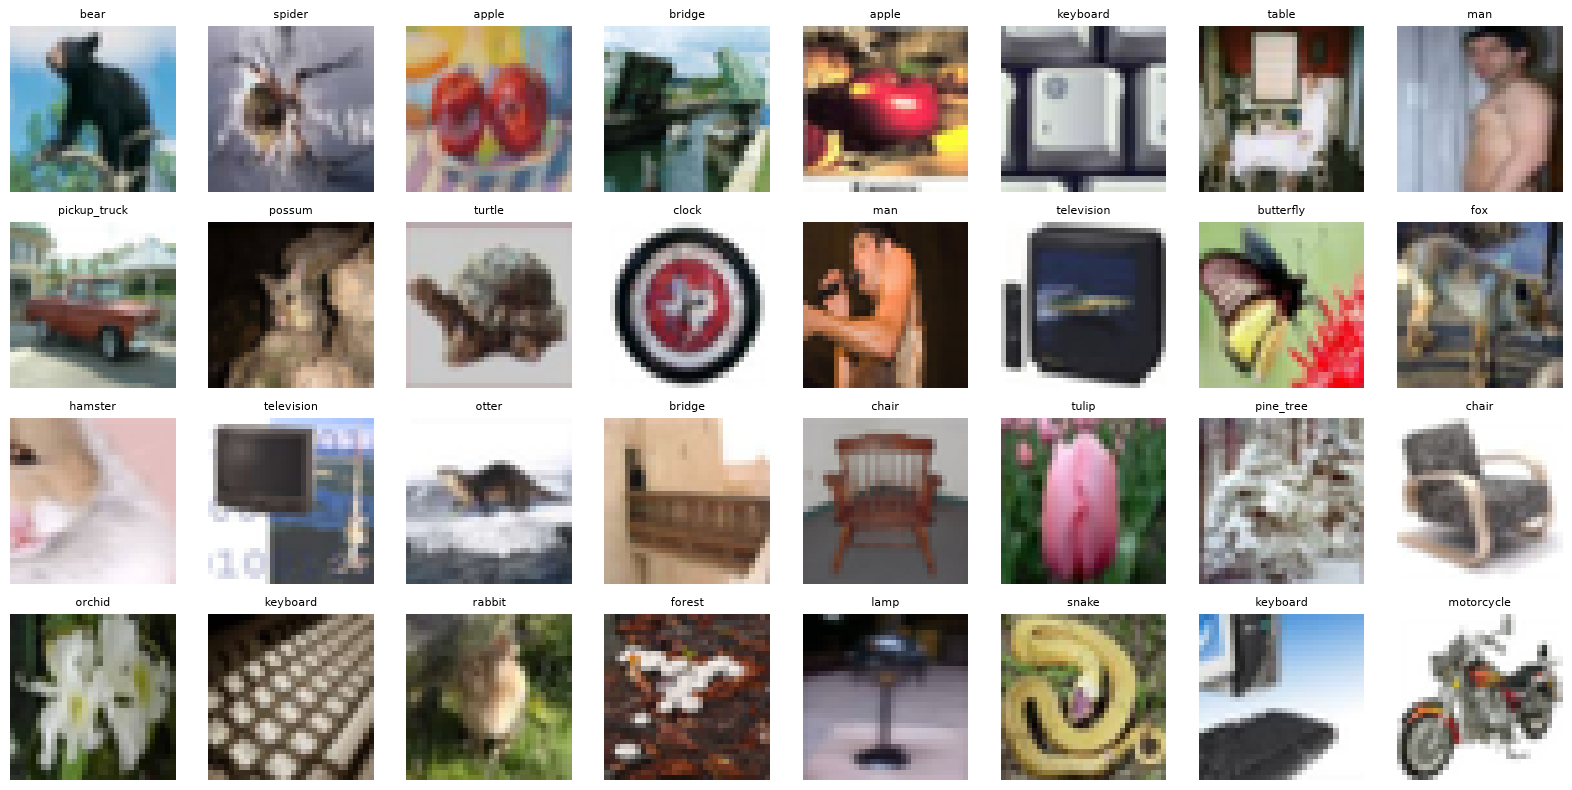

In [1]:
import pickle
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
from PIL import Image
from torch.utils.data import DataLoader, Dataset
from torchvision import transforms

PROJECT_DATA_ROOT = Path(r"G:\Ai\ARIN5101_CourseProject\project_data_80")
BATCH_SIZE = 128
NUM_CLASSES = 80


class CIFAR100PickleDataset(Dataset):

    def __init__(self, root, train=True):
        self.root = Path(root)
        self.data_dir = self.root / "cifar-100-python"
        self.split_name = "train" if train else "test"

        with (self.data_dir / "meta").open("rb") as handle:
            meta = pickle.load(handle, encoding="latin1")
        with (self.data_dir / self.split_name).open("rb") as handle:
            split = pickle.load(handle, encoding="latin1")

        self.data = np.asarray(split["data"], dtype=np.uint8)
        self.targets = list(split["fine_labels"])
        self.coarse_labels = list(split["coarse_labels"])
        self.filenames = list(split["filenames"])
        self.classes = list(meta["fine_label_names"])

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        image = self.data[index].reshape(3, 32, 32).transpose(1, 2, 0)
        return Image.fromarray(image), int(self.targets[index])


class SubsetWithTransform(Dataset):
    def __init__(self, base_dataset, indices, transform=None):
        self.base_dataset = base_dataset
        self.indices = list(indices)
        self.transform = transform

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, index):
        image, target = self.base_dataset[self.indices[index]]
        if self.transform is not None:
            image = self.transform(image)
        return image, target


eval_transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5071, 0.4865, 0.4409),
        std=(0.2673, 0.2564, 0.2762)
    ),
])

train_base = CIFAR100PickleDataset(PROJECT_DATA_ROOT, train=True)
test_base = CIFAR100PickleDataset(PROJECT_DATA_ROOT, train=False)

if len(train_base.classes) != NUM_CLASSES:
    raise ValueError(
        f"Expected {NUM_CLASSES} classes, found {len(train_base.classes)}"
    )

targets = np.asarray(train_base.targets)
rng = np.random.default_rng(42)
train_indices = []
val_indices = []

for class_id in range(NUM_CLASSES):
    class_indices = np.where(targets == class_id)[0]
    if len(class_indices) != 500:
        raise ValueError(
            f"Class {class_id} should have 500 training images, "
            f"found {len(class_indices)}"
        )
    rng.shuffle(class_indices)
    train_indices.extend(class_indices[:400].tolist())
    val_indices.extend(class_indices[400:].tolist())

test_indices = list(range(len(test_base)))

val_set = SubsetWithTransform(train_base, val_indices, eval_transform)
test_set = SubsetWithTransform(test_base, test_indices, eval_transform)

val_loader = DataLoader(
    val_set,
    batch_size=256,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)
test_loader = DataLoader(
    test_set,
    batch_size=256,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

# Baseline uses the same training images but no random augmentation.
baseline_train_set = SubsetWithTransform(
    train_base,
    train_indices,
    eval_transform
)
baseline_train_loader = DataLoader(
    baseline_train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print(f"Classes: {len(train_base.classes)}")
print(f"Training images: {len(train_indices)}")
print(f"Validation images: {len(val_set)}")
print(f"Test images: {len(test_set)}")

sample_rng = np.random.default_rng(123)
sample_indices = sample_rng.choice(len(train_base), size=32, replace=False)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
for axis, index in zip(axes.flat, sample_indices):
    image = train_base.data[index].reshape(3, 32, 32).transpose(1, 2, 0)
    label = train_base.targets[index]
    axis.imshow(image)
    axis.set_title(train_base.classes[label], fontsize=8)
    axis.axis("off")
plt.tight_layout()
plt.show()


## 2. Baseline CNN


In [2]:
import torch
import torch.nn as nn


class BaselineCnn(nn.Module):
    def __init__(self, num_classes=80):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)

        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(64 * 8 * 8, 128)
        self.relu3 = nn.ReLU()
        self.linear2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = self.flatten(x)
        x = self.relu3(self.linear1(x))
        x = self.linear2(x)
        return x


baseline_model = BaselineCnn(num_classes=NUM_CLASSES)
print(baseline_model)
print(f"Trainable parameters: {sum(p.numel() for p in baseline_model.parameters())}")


BaselineCnn(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear1): Linear(in_features=4096, out_features=128, bias=True)
  (relu3): ReLU()
  (linear2): Linear(in_features=128, out_features=80, bias=True)
)
Trainable parameters: 554128


## 3. Baseline CNN training


In [5]:
import copy
import time

import torch


def evaluate(model, loader, loss_fn, device):
    model.eval()
    total_loss = 0.0
    top1_correct = 0
    top5_correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            loss = loss_fn(logits, y_batch)

            batch_size = y_batch.size(0)
            total_loss += loss.item() * batch_size
            _, top5 = logits.topk(5, dim=1)
            top1_correct += (top5[:, 0] == y_batch).sum().item()
            top5_correct += (top5 == y_batch.unsqueeze(1)).sum().item()
            total += batch_size

    return total_loss / total, top1_correct / total, top5_correct / total


MAX_EPOCHS = 40
PATIENCE = 5

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
baseline_model = baseline_model.to(device)
print(f"This CNN is training on {device}")

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(baseline_model.parameters(), lr=0.001)

baseline_best_val_loss = float("inf")
baseline_best_val_top1 = 0.0
baseline_best_state = None
epochs_without_improvement = 0
baseline_start_time = time.perf_counter()

for epoch in range(MAX_EPOCHS):
    baseline_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in baseline_train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = baseline_model(X_batch)
        loss = loss_fn(logits, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        batch_size = y_batch.size(0)
        running_loss += loss.item() * batch_size
        correct += (logits.argmax(1) == y_batch).sum().item()
        total += batch_size

    train_loss = running_loss / total
    train_acc = correct / total
    val_loss, val_top1, val_top5 = evaluate(
        baseline_model, val_loader, loss_fn, device
    )

    print(
        f"Epoch {epoch + 1}/{MAX_EPOCHS} | "
        f"Train loss: {train_loss:.4f}, Train acc: {train_acc:.2%} | "
        f"Val loss: {val_loss:.4f}, Val top-1: {val_top1:.2%}, "
        f"Val top-5: {val_top5:.2%}"
    )

    if val_loss < baseline_best_val_loss:
        baseline_best_val_loss = val_loss
        baseline_best_val_top1 = val_top1
        baseline_best_state = copy.deepcopy(baseline_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(
            f"Early stopping: validation loss has not improved for "
            f"{PATIENCE} consecutive epochs."
        )
        break

if baseline_best_state is not None:
    baseline_model.load_state_dict(baseline_best_state)

baseline_elapsed = time.perf_counter() - baseline_start_time
baseline_training_minutes = baseline_elapsed / 60
print(f"Best validation loss: {baseline_best_val_loss:.4f}")
print(f"Best validation top-1: {baseline_best_val_top1:.2%}")
print(
    f"Baseline training completed in {baseline_elapsed:.2f} seconds "
    f"({baseline_training_minutes:.2f} minutes)"
)


This CNN is training on cuda
Epoch 1/40 | Train loss: 2.2617, Train acc: 40.67% | Val loss: 2.4314, Val top-1: 36.11%, Val top-5: 68.58%
Epoch 2/40 | Train loss: 2.0496, Train acc: 45.45% | Val loss: 2.4444, Val top-1: 36.79%, Val top-5: 68.74%
Epoch 3/40 | Train loss: 1.8825, Train acc: 49.16% | Val loss: 2.3383, Val top-1: 39.21%, Val top-5: 70.83%
Epoch 4/40 | Train loss: 1.7169, Train acc: 53.15% | Val loss: 2.3386, Val top-1: 40.16%, Val top-5: 71.81%
Epoch 5/40 | Train loss: 1.5632, Train acc: 56.94% | Val loss: 2.3877, Val top-1: 39.81%, Val top-5: 71.23%
Epoch 6/40 | Train loss: 1.4050, Train acc: 60.73% | Val loss: 2.5040, Val top-1: 39.83%, Val top-5: 70.44%
Epoch 7/40 | Train loss: 1.2697, Train acc: 64.05% | Val loss: 2.5450, Val top-1: 39.15%, Val top-5: 70.31%
Epoch 8/40 | Train loss: 1.1326, Train acc: 67.77% | Val loss: 2.6469, Val top-1: 39.15%, Val top-5: 70.46%
Early stopping: validation loss has not improved for 5 consecutive epochs.
Best validation loss: 2.3383
Bes

## 4. Baseline CNN test evaluation


In [6]:
baseline_model.eval()

baseline_test_loss, baseline_test_top1, baseline_test_top5 = evaluate(
    baseline_model,
    test_loader,
    loss_fn,
    device
)

print(
    f"Baseline test loss: {baseline_test_loss:.4f} | "
    f"Baseline test top-1: {baseline_test_top1:.2%} | "
    f"Baseline test top-5: {baseline_test_top5:.2%}"
)


Baseline test loss: 2.3287 | Baseline test top-1: 40.21% | Baseline test top-5: 70.62%


## 5. Improved CNN architecture

The model keeps the two convolution layers, two max-pool layers, one 128-unit hidden layer, and 80-class output. BatchNorm is added after both convolution layers and after the hidden linear layer. Data augmentation is handled by the training dataloader, not by the model.

In [7]:
import torch
import torch.nn as nn


class CifarCnnWithBatchNorm(nn.Module):
    def __init__(self, num_classes=80):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.batchnorm1 = nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.batchnorm2 = nn.BatchNorm2d(64)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)

        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(64 * 8 * 8, 128)
        self.batchnorm3 = nn.BatchNorm1d(128)
        self.relu3 = nn.ReLU()
        self.linear2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool1(self.relu1(self.batchnorm1(self.conv1(x))))
        x = self.pool2(self.relu2(self.batchnorm2(self.conv2(x))))
        x = self.flatten(x)
        x = self.relu3(self.batchnorm3(self.linear1(x)))
        x = self.linear2(x)
        return x


improved_model = CifarCnnWithBatchNorm(num_classes=NUM_CLASSES)
print(improved_model)
print(f"Trainable parameters: {sum(p.numel() for p in improved_model.parameters())}")


CifarCnnWithBatchNorm(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batchnorm1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batchnorm2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear1): Linear(in_features=4096, out_features=128, bias=True)
  (batchnorm3): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu3): ReLU()
  (linear2): Linear(in_features=128, out_features=80, bias=True)
)
Trainable parameters: 554576


## 6. Data augmentation for training only

The training images use RandomCrop and RandomHorizontalFlip. Validation and test images use only ToTensor and Normalize.

In [8]:
from torchvision import transforms

aug_train_transform = transforms.Compose([
    transforms.RandomCrop(32, padding=4),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=(0.5071, 0.4865, 0.4409),
        std=(0.2673, 0.2564, 0.2762)
    ),
])

aug_train_set = SubsetWithTransform(
    train_base,
    train_indices,
    aug_train_transform
)
aug_train_loader = DataLoader(
    aug_train_set,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print(f"Augmented training images: {len(aug_train_set)}")
print(f"Validation images: {len(val_set)}")
print(f"Test images: {len(test_set)}")


Augmented training images: 32000
Validation images: 8000
Test images: 8000


## 7. Training with BatchNorm + Data Augmentation


In [9]:
import copy
import time

import numpy as np
import torch


def evaluate(model, loader, loss_fn, device):
    model.eval()
    total_loss = 0.0
    top1_correct = 0
    top5_correct = 0
    total = 0

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            logits = model(X_batch)
            loss = loss_fn(logits, y_batch)

            batch_size = y_batch.size(0)
            total_loss += loss.item() * batch_size
            _, top5 = logits.topk(5, dim=1)
            top1_correct += (top5[:, 0] == y_batch).sum().item()
            top5_correct += (top5 == y_batch.unsqueeze(1)).sum().item()
            total += batch_size

    return total_loss / total, top1_correct / total, top5_correct / total


MAX_EPOCHS = 40
PATIENCE = 5

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
improved_model = improved_model.to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(improved_model.parameters(), lr=0.001)

improved_best_val_loss = float("inf")
improved_best_val_top1 = 0.0
best_state = None
epochs_without_improvement = 0
start_time = time.perf_counter()

for epoch in range(MAX_EPOCHS):
    improved_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in aug_train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = improved_model(X_batch)
        loss = loss_fn(logits, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        batch_size = y_batch.size(0)
        running_loss += loss.item() * batch_size
        correct += (logits.argmax(1) == y_batch).sum().item()
        total += batch_size

    train_loss = running_loss / total
    train_acc = correct / total
    val_loss, val_top1, val_top5 = evaluate(
        improved_model, val_loader, loss_fn, device
    )

    print(
        f"Epoch {epoch + 1}/{MAX_EPOCHS} | "
        f"Train loss: {train_loss:.4f}, Train acc: {train_acc:.2%} | "
        f"Val loss: {val_loss:.4f}, Val top-1: {val_top1:.2%}, "
        f"Val top-5: {val_top5:.2%}"
    )

    if val_loss < improved_best_val_loss:
        improved_best_val_loss = val_loss
        improved_best_val_top1 = val_top1
        best_state = copy.deepcopy(improved_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(
            f"Early stopping: validation loss has not improved for "
            f"{PATIENCE} consecutive epochs."
        )
        break

if best_state is not None:
    improved_model.load_state_dict(best_state)

elapsed = time.perf_counter() - start_time
improved_training_minutes = elapsed / 60
print(f"Best validation loss: {improved_best_val_loss:.4f}")
print(f"Best validation top-1: {improved_best_val_top1:.2%}")
print(f"Training completed in {elapsed:.2f} seconds ({improved_training_minutes:.2f} minutes)")


Epoch 1/40 | Train loss: 3.5109, Train acc: 17.18% | Val loss: 2.9258, Val top-1: 27.57%, Val top-5: 57.90%
Epoch 2/40 | Train loss: 2.8003, Train acc: 29.17% | Val loss: 2.4930, Val top-1: 35.09%, Val top-5: 67.04%
Epoch 3/40 | Train loss: 2.5220, Train acc: 34.48% | Val loss: 2.2901, Val top-1: 39.88%, Val top-5: 71.39%
Epoch 4/40 | Train loss: 2.3610, Train acc: 37.86% | Val loss: 2.1983, Val top-1: 41.33%, Val top-5: 73.09%
Epoch 5/40 | Train loss: 2.2492, Train acc: 40.22% | Val loss: 2.1907, Val top-1: 42.14%, Val top-5: 73.14%
Epoch 6/40 | Train loss: 2.1697, Train acc: 42.16% | Val loss: 2.0411, Val top-1: 45.14%, Val top-5: 76.12%
Epoch 7/40 | Train loss: 2.0997, Train acc: 43.69% | Val loss: 2.0168, Val top-1: 45.34%, Val top-5: 76.85%
Epoch 8/40 | Train loss: 2.0452, Train acc: 45.17% | Val loss: 2.0107, Val top-1: 45.76%, Val top-5: 77.00%
Epoch 9/40 | Train loss: 1.9888, Train acc: 46.11% | Val loss: 1.9795, Val top-1: 46.16%, Val top-5: 77.98%
Epoch 10/40 | Train loss: 1.

## 8. Improved CNN test evaluation


In [10]:
improved_model.eval()

improved_test_loss, improved_test_top1, improved_test_top5 = evaluate(
    improved_model,
    test_loader,
    loss_fn,
    device
)

print(
    f"Improved test loss: {improved_test_loss:.4f} | "
    f"Improved test top-1: {improved_test_top1:.2%} | "
    f"Improved test top-5: {improved_test_top5:.2%}"
)


Improved test loss: 1.7465 | Improved test top-1: 53.86% | Improved test top-5: 81.84%


## 9. Baseline vs improved model comparison

This final cell prints the test performance of both models side by side.
The comparison uses the same test set and the best validation-loss checkpoint
from each training run.

The improved model should outperform the baseline if BatchNorm + Data
Augmentation is useful for this dataset.

In [14]:
print("Model comparison on the same test set")
print("=" * 50)
print(
    f"Baseline | "
    f"val top-1: {baseline_best_val_top1:.2%} | "
    f"test top-1: {baseline_test_top1:.2%} | "
    f"test top-5: {baseline_test_top5:.2%} | "
    f"time: {baseline_training_minutes:.2f} mins"
)
print(
    f"BN + Aug | "
    f"val top-1: {improved_best_val_top1:.2%} | "
    f"test top-1: {improved_test_top1:.2%} | "
    f"test top-5: {improved_test_top5:.2%} | "
    f"time: {improved_training_minutes:.2f} mins"
)
print(
    f"Top-1 improvement: "
    f"{(improved_test_top1 - baseline_test_top1) * 100:.2f}%"
)
print(
    f"Top-5 improvement: "
    f"{(improved_test_top5 - baseline_test_top5) * 100:.2f}%"
)


Model comparison on the same test set
Baseline | val top-1: 39.21% | test top-1: 40.21% | test top-5: 70.62% | time: 3.51 min
BN + Aug | val top-1: 52.33% | test top-1: 53.86% | test top-5: 81.84% | time: 19.43 min
Top-1 improvement: 13.65%
Top-5 improvement: 11.21%


## 10. Tuned model: three convolutions 32/64/128 + hidden 256 + BatchNorm + Data Augmentation

This is one combined tuned model, not several separate models.

Architecture:

- Conv 3 → 32, BatchNorm, ReLU, MaxPool
- Conv 32 → 64, BatchNorm, ReLU, MaxPool
- Conv 64 → 128, BatchNorm, ReLU, MaxPool
- Flatten: 128 × 4 × 4 = 2048
- Linear 2048 → 256
- BatchNorm1d(256)
- ReLU
- Linear 256 → 80

Training uses the existing augmented training loader, the same validation set,
Adam optimizer, learning rate, maximum epoch budget, and early-stopping
patience as the previous models.

In [15]:
import torch
import torch.nn as nn


class CifarCnnTuned(nn.Module):
    def __init__(self, num_classes=80):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 32, kernel_size=3, padding=1)
        self.batchnorm1 = nn.BatchNorm2d(32)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool2d(2)

        self.conv2 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.batchnorm2 = nn.BatchNorm2d(64)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool2d(2)

        self.conv3 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.batchnorm3 = nn.BatchNorm2d(128)
        self.relu3 = nn.ReLU()
        self.pool3 = nn.MaxPool2d(2)

        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(128 * 4 * 4, 256)
        self.batchnorm4 = nn.BatchNorm1d(256)
        self.relu4 = nn.ReLU()
        self.linear2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = self.pool1(self.relu1(self.batchnorm1(self.conv1(x))))
        x = self.pool2(self.relu2(self.batchnorm2(self.conv2(x))))
        x = self.pool3(self.relu3(self.batchnorm3(self.conv3(x))))
        x = self.flatten(x)
        x = self.relu4(self.batchnorm4(self.linear1(x)))
        x = self.linear2(x)
        return x


tuned_model = CifarCnnTuned(num_classes=NUM_CLASSES)
print(tuned_model)
print(f"Trainable parameters: {sum(p.numel() for p in tuned_model.parameters())}")


CifarCnnTuned(
  (conv1): Conv2d(3, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batchnorm1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu1): ReLU()
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batchnorm2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu2): ReLU()
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv3): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (batchnorm3): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu3): ReLU()
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (flatten): Flatten(start_dim=1, end_dim=-1)
  (linear1): Linear(in_features=2048, out_features=256, bias=True)
  (batc

## 11. Training the tuned model


In [16]:
import copy
import time

import torch


TUNED_MAX_EPOCHS = 40
TUNED_PATIENCE = 5

torch.manual_seed(42)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
tuned_model = tuned_model.to(device)

loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(tuned_model.parameters(), lr=0.001)

tuned_best_val_loss = float("inf")
tuned_best_val_top1 = 0.0
tuned_best_state = None
epochs_without_improvement = 0
tuned_start_time = time.perf_counter()

for epoch in range(TUNED_MAX_EPOCHS):
    tuned_model.train()
    running_loss = 0.0
    correct = 0
    total = 0

    for X_batch, y_batch in aug_train_loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        logits = tuned_model(X_batch)
        loss = loss_fn(logits, y_batch)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        batch_size = y_batch.size(0)
        running_loss += loss.item() * batch_size
        correct += (logits.argmax(1) == y_batch).sum().item()
        total += batch_size

    train_loss = running_loss / total
    train_acc = correct / total
    val_loss, val_top1, val_top5 = evaluate(
        tuned_model, val_loader, loss_fn, device
    )

    print(
        f"Epoch {epoch + 1}/{TUNED_MAX_EPOCHS} | "
        f"Train loss: {train_loss:.4f}, Train acc: {train_acc:.2%} | "
        f"Val loss: {val_loss:.4f}, Val top-1: {val_top1:.2%}, "
        f"Val top-5: {val_top5:.2%}"
    )

    if val_loss < tuned_best_val_loss:
        tuned_best_val_loss = val_loss
        tuned_best_val_top1 = val_top1
        tuned_best_state = copy.deepcopy(tuned_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= TUNED_PATIENCE:
        print(
            f"Early stopping: validation loss has not improved for "
            f"{TUNED_PATIENCE} consecutive epochs."
        )
        break

if tuned_best_state is not None:
    tuned_model.load_state_dict(tuned_best_state)

tuned_elapsed = time.perf_counter() - tuned_start_time
tuned_training_minutes = tuned_elapsed / 60
print(f"Best validation loss: {tuned_best_val_loss:.4f}")
print(f"Best validation top-1: {tuned_best_val_top1:.2%}")
print(
    f"Tuned training completed in {tuned_elapsed:.2f} seconds "
    f"({tuned_training_minutes:.2f} minutes)"
)


Epoch 1/40 | Train loss: 3.3199, Train acc: 19.64% | Val loss: 2.7756, Val top-1: 28.94%, Val top-5: 60.74%
Epoch 2/40 | Train loss: 2.5897, Train acc: 32.81% | Val loss: 2.4052, Val top-1: 36.41%, Val top-5: 68.49%
Epoch 3/40 | Train loss: 2.3018, Train acc: 39.21% | Val loss: 2.2013, Val top-1: 40.75%, Val top-5: 72.61%
Epoch 4/40 | Train loss: 2.1218, Train acc: 43.00% | Val loss: 2.0441, Val top-1: 45.04%, Val top-5: 76.22%
Epoch 5/40 | Train loss: 1.9866, Train acc: 46.25% | Val loss: 1.9479, Val top-1: 46.92%, Val top-5: 77.90%
Epoch 6/40 | Train loss: 1.8776, Train acc: 48.50% | Val loss: 1.9158, Val top-1: 47.86%, Val top-5: 78.74%
Epoch 7/40 | Train loss: 1.7919, Train acc: 50.49% | Val loss: 1.9002, Val top-1: 48.16%, Val top-5: 78.84%
Epoch 8/40 | Train loss: 1.7116, Train acc: 52.67% | Val loss: 1.8104, Val top-1: 50.41%, Val top-5: 80.34%
Epoch 9/40 | Train loss: 1.6367, Train acc: 54.20% | Val loss: 1.8187, Val top-1: 50.38%, Val top-5: 80.42%
Epoch 10/40 | Train loss: 1.

## 13. Test evaluation for the tuned model


In [17]:
tuned_model.eval()

tuned_test_loss, tuned_test_top1, tuned_test_top5 = evaluate(
    tuned_model,
    test_loader,
    loss_fn,
    device
)

print(
    f"Tuned model test loss: {tuned_test_loss:.4f} | "
    f"Tuned test top-1: {tuned_test_top1:.2%} | "
    f"Tuned test top-5: {tuned_test_top5:.2%}"
)


Tuned model test loss: 1.6194 | Tuned test top-1: 56.39% | Tuned test top-5: 83.81%
